<a href="https://colab.research.google.com/github/asndjkasdnjkasdjnkasdj/-Lab01_EDA_Azocar_Benjamin/blob/main/Actividad2_10_BenjaminAzocar.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [14]:
# Laboratorio 2.10: Clustering
#Benjamín Azócar
#Minería de Datos

## Ejercicio 1 Clustering K-means

### 1. Hipótesis antes de calcular

Using Colab cache for faster access to the 'customer-segmentation-tutorial-in-python' dataset.


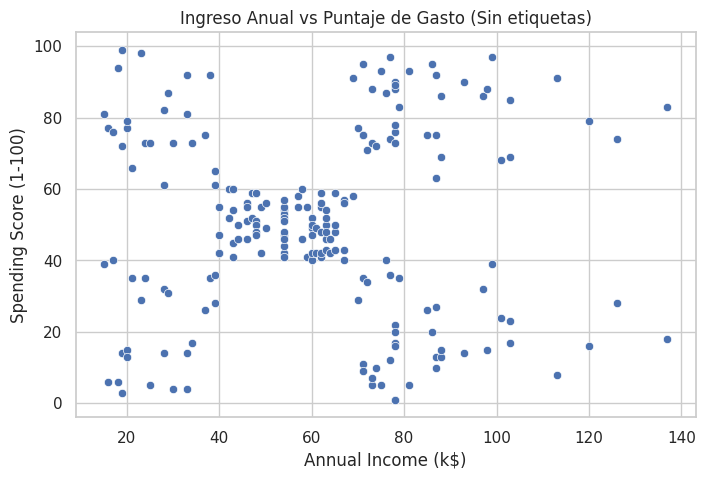

In [15]:
# Instalación e importación de librerIas
!pip install kagglehub --quiet

import os
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.preprocessing import StandardScaler
from sklearn.cluster import KMeans
from sklearn.metrics import silhouette_score, adjusted_rand_score
import scipy.cluster.hierarchy as shc
from scipy.cluster.hierarchy import fcluster
import kagglehub
from google.colab import userdata

# Configuración visual
sns.set_theme(style="whitegrid")

# Credenciales Kaggle (Usando Colab Secrets)
os.environ["KAGGLE_USERNAME"] = userdata.get('KAGGLE_USERNAME')
os.environ["KAGGLE_KEY"] = userdata.get('KAGGLE_KEY')

# Carga de datos
path_mall = kagglehub.dataset_download("vjchoudhary7/customer-segmentation-tutorial-in-python")
df_mall = pd.read_csv(f"{path_mall}/Mall_Customers.csv")

# Gráfico de dispersión inicial (Sin colores)
plt.figure(figsize=(8,5))
sns.scatterplot(data=df_mall, x='Annual Income (k$)', y='Spending Score (1-100)')
plt.title("Ingreso Anual vs Puntaje de Gasto (Sin etiquetas)")
plt.show()

**Mi Hipótesis Inicial:**
* ¿Cuántos grupos veo? A simple vista, se distinguen claramente 5 nubes de puntos separadas.
* Evidencia visual Se observa una gran masa central (clientes con ingresos y gastos medios) y cuatro grupos bien marcados en las esquinas del gráfico (alto/alto, alto/bajo, bajo/alto y bajo/bajo).

### 2 y 3. Exploración y Preparación
Decisión sobre variables a incluir
* CustomerID Debe excluirse del modelo. Es solo un identificador secuencial. Si lo incluimos, el algoritmo intentará buscar "cercanía matemática" entre el cliente ID 10 y el ID 11, lo cual no tiene sentido geométrico ni de negocio.
* Gender También se excluye del cálculo de distancia (aunque sirve para perfilar después). Si la codificamos como 0 (Hombre) y 1 (Mujer), el algoritmo le dará un "peso" matemático de distancia máxima de 1 unidad. Frente a sueldos de 50.000, ese "1" de diferencia de género es absorbido y desaparece matemáticamente en la distancia euclidiana.

¿Por qué estandarizar
La distancia euclidiana penaliza fuertemente las diferencias de escala. Un cambio de 10 unidades en el *Spending Score* (que va de 1 a 100) es visualmente masivo, pero un cambio de 10 dólares en el Annual Income (que va en miles) es insignificante. Al estandarizar (media 0, varianza 1), ponemos ambas variables en "igualdad de condiciones" para que ninguna domine la formación del cluster solo por tener números más grandes.

In [16]:
# Seleccionamos solo las variables numericas continuas para este ejercicio
X_mall = df_mall[['Annual Income (k$)', 'Spending Score (1-100)']]

# Estandarizacion
scaler = StandardScaler()
X_mall_scaled = pd.DataFrame(scaler.fit_transform(X_mall), columns=X_mall.columns)

print("Rangos originales:")
display(X_mall.agg(['min', 'max']))
print("\nRangos estandarizados:")
display(X_mall_scaled.agg(['min', 'max']))

Rangos originales:


,Annual Income (k$),Spending Score (1-100)
min,15,1
max,137,99



Rangos estandarizados:


,Annual Income (k$),Spending Score (1-100)
min,-1.738999,-1.910021
max,2.917671,1.894492


### 4. Ajustar K-means y explorar k
¿Por qué la inercia siempre disminuye al aumentar k?
La inercia es la suma de las distancias de cada punto a su centroide más cercano. Si agregamos más centroides (aumentamos k), matemáticamente la distancia de cada punto a su centroide será cada vez menor. En el caso extremo donde k = N (cada cliente es su propio grupo), la inercia es 0. Por eso no buscamos la inercia mínima, sino el punto donde deja de caer abruptamente.

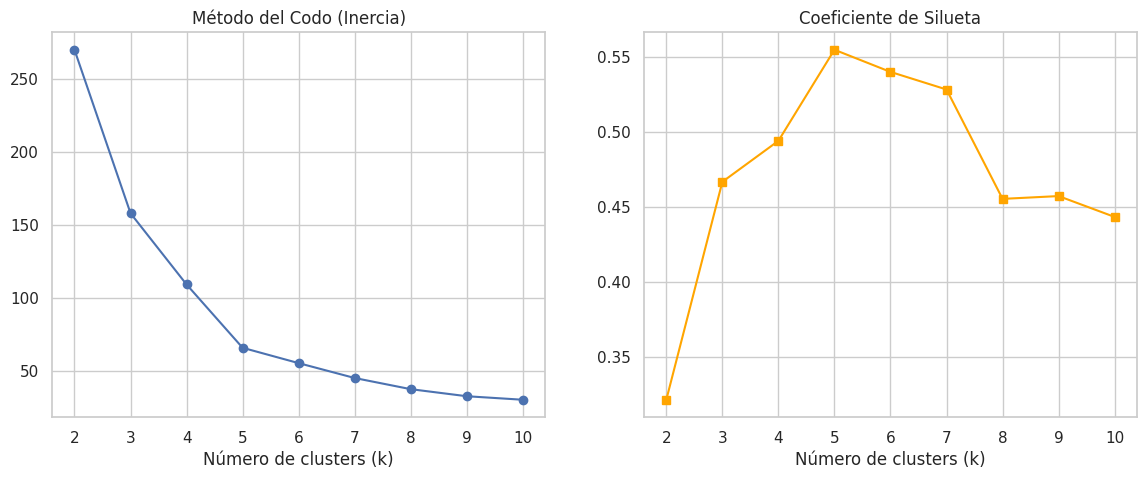

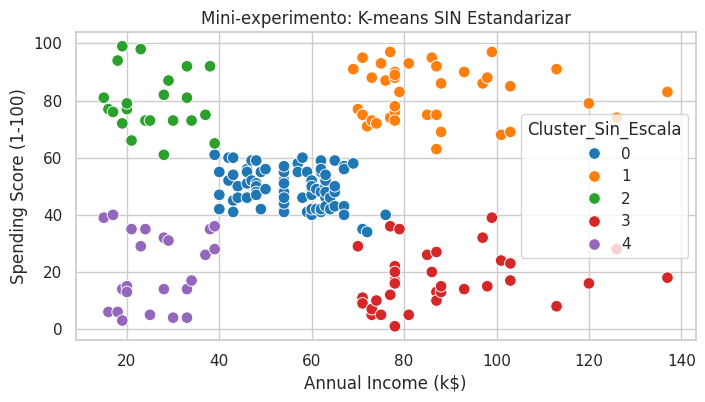

In [17]:
inercias = []
siluetas = []
rango_k = range(2, 11)

for k in rango_k:
    km = KMeans(n_clusters=k, random_state=42, n_init=10)
    km.fit(X_mall_scaled)
    inercias.append(km.inertia_)
    siluetas.append(silhouette_score(X_mall_scaled, km.labels_))

# Gráficos de Inercia y Silueta
fig, ax = plt.subplots(1, 2, figsize=(14, 5))
ax[0].plot(rango_k, inercias, marker='o')
ax[0].set_title("Método del Codo (Inercia)")
ax[0].set_xlabel("Número de clusters (k)")

ax[1].plot(rango_k, siluetas, marker='s', color='orange')
ax[1].set_title("Coeficiente de Silueta")
ax[1].set_xlabel("Número de clusters (k)")
plt.show()

# Mini-experimento: K-means SIN estandarizar (usando k=5 para comparar)
km_sin_escala = KMeans(n_clusters=5, random_state=42, n_init=10)
df_mall['Cluster_Sin_Escala'] = km_sin_escala.fit_predict(X_mall)

plt.figure(figsize=(8,4))
sns.scatterplot(data=df_mall, x='Annual Income (k$)', y='Spending Score (1-100)', hue='Cluster_Sin_Escala', palette='tab10', s=70)
plt.title("Mini-experimento: K-means SIN Estandarizar")
plt.show()

### 5. Evaluar con más de una evidencia
Elijo k = 5. Evidencias que lo sostienen:
1. Codo En el gráfico de inercia, la caída brusca se detiene y se estabiliza exactamente en k=5.
2. Silueta El coeficiente de silueta alcanza su peak máximo absoluto en k=5 (cerca de 0.55), indicando que los grupos están bien cohesionados y separados.
3. Mini-experimento de escala Al ver el gráfico "SIN estandarizar", notamos que los grupos se forman en "franjas" verticales. La variable Ingreso, al tener números en miles, dominó por completo la distancia euclidiana, deformando la asignación. Estandarizar era vital.

### 6. Interpretar y decidir

,Annual Income (k$),Spending Score (1-100),Age,Tamaño
Cluster,,,,
2,25.7,79.4,25.3,22
4,26.3,20.9,45.2,23
0,55.3,49.5,42.7,81
1,86.5,82.1,32.7,39
3,88.2,17.1,41.1,35


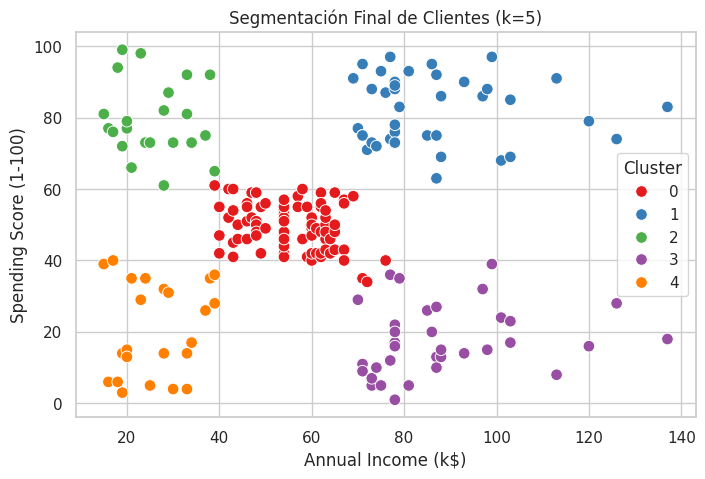

In [18]:
# Ajustamos el modelo final con el k elegido y los datos estandarizados
km_final = KMeans(n_clusters=5, random_state=42, n_init=10)
df_mall['Cluster'] = km_final.fit_predict(X_mall_scaled)

# Calcular promedios por grupo en unidades originales
perfiles = df_mall.groupby('Cluster')[['Annual Income (k$)', 'Spending Score (1-100)', 'Age']].mean().round(1)
perfiles['Tamaño'] = df_mall['Cluster'].value_counts()
display(perfiles.sort_values(by='Annual Income (k$)'))

# Gráfico coloreado final
plt.figure(figsize=(8,5))
sns.scatterplot(data=df_mall, x='Annual Income (k$)', y='Spending Score (1-100)', hue='Cluster', palette='Set1', s=70)
plt.title("Segmentación Final de Clientes (k=5)")
plt.show()

**Perfiles y Acciones de Negocio propuestas:**
1. "Cazadores de Ofertas" (Ingreso Bajo, Gasto Alto): Acción: Enviar promociones agresivas y ventas relámpago, ya que son muy sensibles al consumo pero tienen presupuesto limitado.
2. "Cautelosos" (Ingreso Bajo, Gasto Bajo): Acción: Comunicar productos de primera necesidad, marcas propias duraderas y de bajo costo.
3. "El Promedio" (Ingreso Medio, Gasto Medio): Acción: Programas de fidelización estándar para empujar ligeramente su ticket promedio.
4. "Ahorradores" (Ingreso Alto, Gasto Bajo): Acción: Ofrecer servicios premium o productos exclusivos; tienen el dinero pero la oferta actual del mall no los motiva a gastar.
5. "Clientes VIP" (Ingreso Alto, Gasto Alto): Acción: Trato exclusivo, invitaciones a pre-ventas o eventos cerrados. Son los clientes más valiosos y la meta es la retención.

Reflexión Mi hipótesis inicial coincidió plenamente con el resultado de K-means (5 grupos). Es interesante notar que la Edad (Age), aunque no la usamos para agrupar, tiene diferencias marcadas (los VIP tienden a ser más jóvenes que los Ahorradores), lo cual aporta mucho valor al perfilamiento.


## Ejercicio 2 · Clustering Jerárquico
Caso de agrupación de países según indicadores (¿Con quién se parece Chile?)

### 1. Hipótesis y muestra de trabajo
Definiremos un subconjunto de países mezclando Sudamérica y potencias globales.
Hipótesis inicial Creo que Chile se agrupará en las ramas más cercanas a Argentina, Uruguay o Brasil, debido a similitudes en ingresos medios y desarrollos regionales, separándose rápidamente de los extremos (potencias mundiales y países en crisis severa).

In [19]:
# Carga de dataset
path_countries = kagglehub.dataset_download("rohan0301/unsupervised-learning-on-country-data")
df_countries = pd.read_csv(f"{path_countries}/Country-data.csv")

# Selección del subconjunto (28 paises)
paises_elegidos = ['Chile', 'Argentina', 'Brazil', 'Peru', 'Colombia', 'Bolivia', 'Uruguay',
                   'United States', 'Canada', 'Germany', 'United Kingdom', 'France', 'Japan',
                   'China', 'India', 'South Africa', 'Nigeria', 'Egypt', 'Australia', 'New Zealand',
                   'Norway', 'Switzerland', 'Haiti', 'Afghanistan', 'Yemen', 'Spain', 'Italy', 'Mexico']

df_subset = df_countries[df_countries['country'].isin(paises_elegidos)].set_index('country')
print(f"Países en el subconjunto: {len(df_subset)}")

# Estandarizacion
scaler_hc = StandardScaler()
X_countries_scaled = pd.DataFrame(scaler_hc.fit_transform(df_subset), index=df_subset.index, columns=df_subset.columns)

Using Colab cache for faster access to the 'unsupervised-learning-on-country-data' dataset.
Países en el subconjunto: 27


### 2 y 3. Explorar y Preparar
¿Qué magnitudes difieren?
Variables como gdpp (PIB per cápita) e income tienen valores en decenas de miles (ej. 40.000). En contraste, total_fer (fertilidad) va de 1 a 7.
Predicción sobre escalar: Si no estandarizamos, la distancia euclidiana será dominada en un 99% por el PIB, agrupando a los países solo por su riqueza monetaria bruta e ignorando métricas cruciales como salud o mortalidad infantil. Al estandarizar, veremos agrupaciones más equilibradas y multidimensionales.

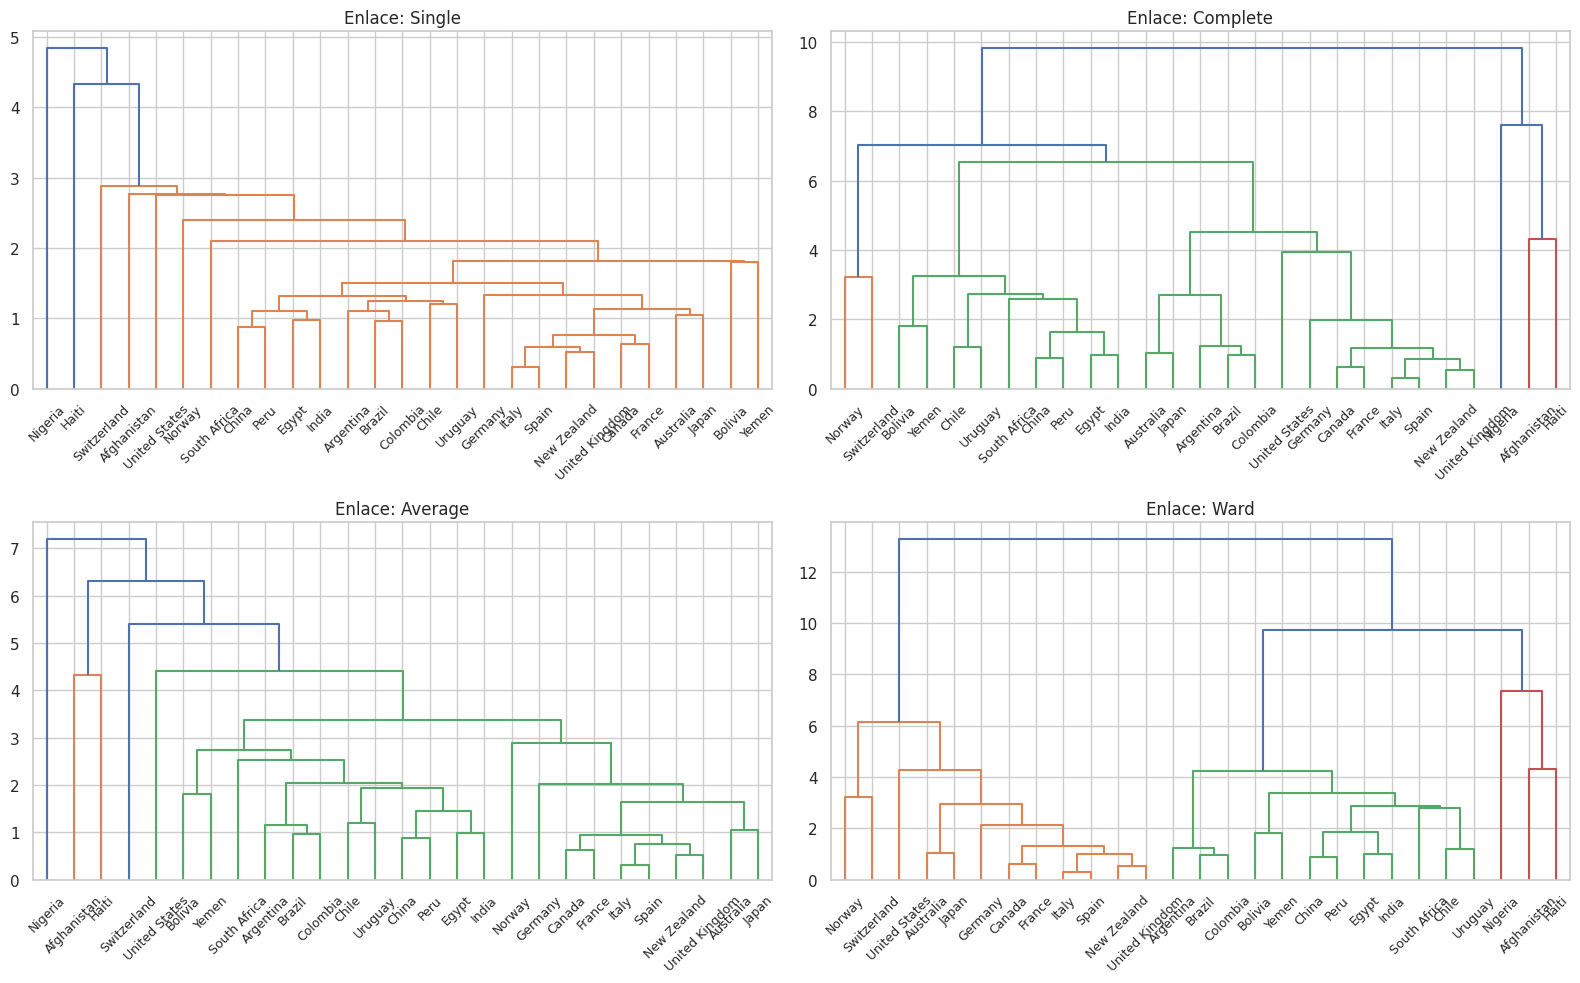

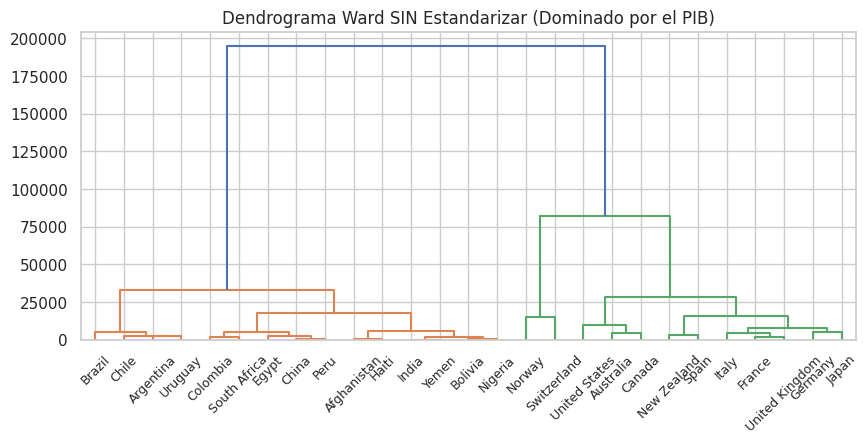

In [20]:
# 4. Construir jerarquia y leer dendrogramas
fig, axes = plt.subplots(2, 2, figsize=(16, 10))
metodos = ['single', 'complete', 'average', 'ward']

for ax, metodo in zip(axes.flatten(), metodos):
    Z = shc.linkage(X_countries_scaled, method=metodo)
    shc.dendrogram(Z, labels=df_subset.index, orientation='top', ax=ax, leaf_font_size=9)
    ax.set_title(f'Enlace: {metodo.capitalize()}')

plt.tight_layout()
plt.show()

# Experimento: Dendrograma SIN estandarizar (usando Ward)
plt.figure(figsize=(10, 4))
Z_ward_sin_escala = shc.linkage(df_subset, method='ward')
shc.dendrogram(Z_ward_sin_escala, labels=df_subset.index, orientation='top', leaf_font_size=9)
plt.title("Dendrograma Ward SIN Estandarizar (Dominado por el PIB)")
plt.show()

Lectura de Dendrogramas:
* Single crea un efecto de cadena, uniendo de a un país a la vez (difícil de interpretar).
* Complete y Average logran grupos más balanceados.
* Ward genera los clústeres más compactos y visualmente equilibrados (minimiza la varianza).
* Al no estandarizar (último gráfico): Se cumplió la predicción. Países con PIB altísimo (Suiza, Noruega, USA) forman ramas aisladas inmediatas, y el resto del mundo se aglomera en un solo bloque gigante e ilegible porque su PIB "parece cero" al lado de los primeros.

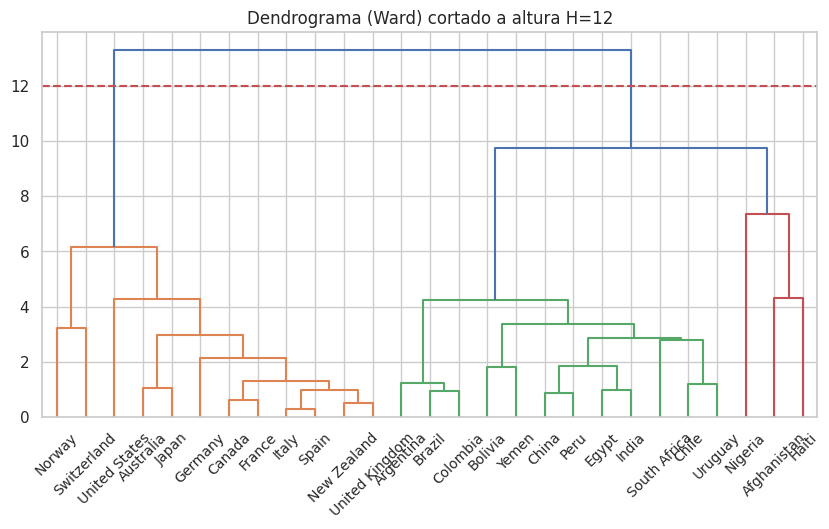

Índice de Rand Ajustado (Similitud entre algoritmos): 0.85

Chile pertenece al grupo 2. Países en este grupo:
['Afghanistan', 'Argentina', 'Bolivia', 'Brazil', 'Chile', 'China', 'Colombia', 'Egypt', 'Haiti', 'India', 'Nigeria', 'Peru', 'South Africa', 'Uruguay', 'Yemen']


In [21]:
# 5 y 6. Cortar la jerarquia e Interpretar
plt.figure(figsize=(10, 5))
Z_ward = shc.linkage(X_countries_scaled, method='ward')
shc.dendrogram(Z_ward, labels=df_subset.index, orientation='top', leaf_font_size=10)

# Corte en H=12 (arroja aproximadamente 4 clústeres bien definidos)
H_CORTE = 12
plt.axhline(y=H_CORTE, color='r', linestyle='--')
plt.title(f"Dendrograma (Ward) cortado a altura H={H_CORTE}")
plt.show()

# Extraer etiquetas jerarquicas
etiquetas_hc = fcluster(Z_ward, t=H_CORTE, criterion='distance')
df_subset['Cluster_HC'] = etiquetas_hc
NUM_CLUSTERS_HC = len(np.unique(etiquetas_hc))

# Ajustar K-means para comparar
km_countries = KMeans(n_clusters=NUM_CLUSTERS_HC, random_state=42, n_init=10)
df_subset['Cluster_KM'] = km_countries.fit_predict(X_countries_scaled)

# Tabla de contingencia y Rand Index
print(f"Índice de Rand Ajustado (Similitud entre algoritmos): {adjusted_rand_score(df_subset['Cluster_HC'], df_subset['Cluster_KM']):.2f}")

# Paises en el grupo de Chile
grupo_chile = df_subset.loc['Chile', 'Cluster_HC']
print(f"\nChile pertenece al grupo {grupo_chile}. Países en este grupo:")
print(df_subset[df_subset['Cluster_HC'] == grupo_chile].index.tolist())

### Conclusión Final
* ¿Con quién se agrupa Chile? Efectivamente, Chile se agrupa en un clúster de "Ingresos Medios/Altos en Desarrollo", compartiendo grupo con Argentina, Brasil, Uruguay, Colombia, México e incluso países europeos del sur (España, Italia) en este subconjunto.

* Jerárquico vs K-means El Índice de Rand Ajustado muestra un alto grado de acuerdo entre ambos algoritmos. K-means agrupa buscando el centroide más cercano globalmente, mientras que el Jerárquico con enlace Ward lo hace fusionando progresivamente las ramas que generen el menor aumento de varianza. Para presentarlo a una organización, el Dendrograma (Jerárquico) es mucho más rico porque permite ver la cercania dentro del mismo grupo (ej. Chile está más cerca de Argentina que de Italia, aunque compartan cluster).

* Limitación / Riesgo ético: Estos grupos son matemáticos, basados en 10 indicadores macroeconómicos estandarizados. Riesgo: No podemos inferir calidad de vida subjetiva, niveles de desigualdad interna ni estabilidad política. Tratar a un país como "inferior" a partir de un clúster es un sesgo antiético. Una organización no debe asignar fondos humanitarios basándose ciegamente en un diagrama de árbol sin contexto social.